### Top edges

In [459]:
# create circuits from top edges

In [460]:
import os
import json
source_relation= 'all'
desired_relation = 'all'
model_mode='clm'
model_mode_outer = model_mode+"_small"
filtered = True
inverse = True
if inverse:
    model_mode_outer = model_mode_outer+'_inv'
    
seeds = [42, 91, 532, 438, 793,
     156, 284, 907, 63, 419,
     712, 35, 668, 501, 229,
     874, 94, 360, 781, 147,
     590, 18, 946, 312, 655,
     87, 478, 821, 204, 739]

result_dir = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/'
dicts = []

for i,seed in enumerate(seeds):
    path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/top_edge_names_raw_{desired_relation}.json'
    print(f'{i} readng from {path}')
    with open(path,'r') as f:
        data = json.load(f)
        #print(len(data))
    dicts.append(data)

from collections import defaultdict
result = defaultdict(int)
#avg = defaultdict(int)
for d in dicts:
    vmin = min(d.values())
    vmax = max(d.values())
    for k, v in d.items():
        result[k] += (v - vmin) / (vmax - vmin)
        #result[k] += v

result = dict(result)
#avg = dict(avg)

for k, v in result.items():
    result[k] = v/len(seeds)

result_filtered = result

if filtered:
    common_keys = set(result.keys())
    for d in dicts:
        common_keys = common_keys.intersection(d.keys())
    
    result_filtered = {k:result[k] for k in common_keys}

print(len(result))
print(len(result_filtered))

top_1000_edges_raw = dict(sorted(result_filtered.items(), 
                                   key=lambda x: abs(x[1]), 
                                   reverse=True)[:1000])

os.makedirs(result_dir, exist_ok=True)
edge_names_file_raw = os.path.join(result_dir, f'top_1000_edges.json')
with open(edge_names_file_raw, 'w') as f:
    json.dump(top_1000_edges_raw, f, indent=4) #top_1000_edges_raw
    print(f'Saved top edge names to {edge_names_file_raw}')

0 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_42/all/top_edge_names_raw_all.json
1 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_91/all/top_edge_names_raw_all.json
2 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_532/all/top_edge_names_raw_all.json
3 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_438/all/top_edge_names_raw_all.json
4 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_793/all/top_edge_names_raw_all.json
5 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_156/all/top_edge_names_raw_all.json
6 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_284/all/top_edge_names_raw_all.json
7 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_907/all/top_edge_names_raw_all.json
8 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_63/all/top_e

## averageing  falthfulness_score_all.json while learning

In [337]:
fsc_dicts = []
for i,seed in enumerate(seeds):
    path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
    print(f'{i} readng from {path}')
    with open(path,'r') as f:
        data = json.load(f)
        #print(len(data))
    #if None not in data.values():
    fsc_dicts.append(data)
print(len(fsc_dicts))
print(fsc_dicts[0])

for d in fsc_dicts:
    if '10001' in d.keys():
        d['10000'] = d['10001']
        print(d.keys())
number_of_runs = len(fsc_dicts)


result = {k:sum(d[k] for d in fsc_dicts)/number_of_runs for k in fsc_dicts[0]}


fsc_avg_file = os.path.join(result_dir, f'falthfulness_score.json')
with open(fsc_avg_file, 'w') as f:
    json.dump(result, f, indent=4) #top_1000_edges_raw
    print(f'avg faithfulness score {fsc_avg_file}')

0 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_42/all/falthfulness_score_all.json
1 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_91/all/falthfulness_score_all.json
2 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_532/all/falthfulness_score_all.json
3 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_438/all/falthfulness_score_all.json
4 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_793/all/falthfulness_score_all.json
5 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_156/all/falthfulness_score_all.json
6 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_284/all/falthfulness_score_all.json
7 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_907/all/falthfulness_score_all.json
8 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_63/all/falthfulness_score_all.json
9 re

In [162]:
print(len(result))
print(len(result_filtered))

28
4978


In [261]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
print(result_dir)
def plot_with_cnfiin(dicts, save_path=None):
    
    sns.set_style("whitegrid")
    df = pd.DataFrame(dicts)
    #print(df)
    df_long = df.melt(var_name="key", value_name="value")
    df_long["key"] = df_long["key"].astype(float)
    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df_long,
        x="key",
        y="value",
        estimator="mean",
        errorbar=("ci", 95),   # shaded confidence band
        marker="o"
    )

    plt.xscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.7)
    plt.xlabel("number of Edges (log scale)", fontsize=14)
    plt.ylabel("Faithfulness score", fontsize=14)
    plt.title("Mean with 95% Confidence Interval", fontsize=16)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")
    plt.show()

    

/srv/data1/abhidipbhatt/output/DC_exp/clm_small/all/all_clm_ALL_seeds/


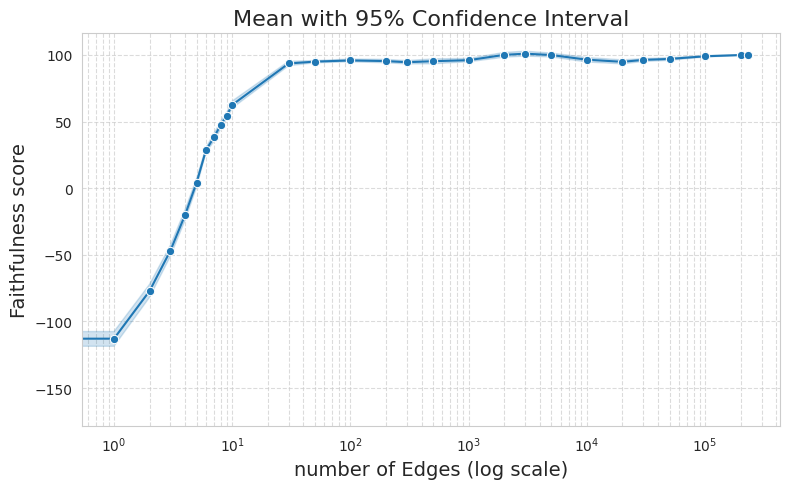

In [338]:
image_name = os.path.join(result_dir, 'plot_faithfulness.png')
plot_with_cnfiin(fsc_dicts,None)

In [344]:
#save as above but plot several experiments togather. Labels is the list of experiment names. list_of_dicts is a list where each element is a list 
#of dicts. Each list of dict is coming from 30 runs (differing by only seed value) under an experiment
def plot_multiple_with_cnfiin(list_of_dicts, labels, save_path=None):
    """
    Plot multiple lists of dicts in the same figure with shaded confidence intervals.
    Each dataset has a different marker and color.

    Args:
        list_of_dicts: list of datasets, each is a list of dicts with same keys
        labels: list of labels (same length as list_of_dicts) for the legend
    """
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    sns.set_style("whitegrid")
    
    # Combine all datasets into one long DataFrame with a "dataset" column
    all_data = []
    for data, label in zip(list_of_dicts, labels):
        df = pd.DataFrame(data)
        df_long = df.melt(var_name="key", value_name="value")
        df_long["key"] = df_long["key"].astype(float)
        df_long["dataset"] = label
        all_data.append(df_long)
    
    combined_df = pd.concat(all_data, ignore_index=True)
    
    plt.figure(figsize=(8, 5))
    
    # Use hue for color and style for marker
    sns.lineplot(
        data=combined_df,
        x="key",
        y="value",
        hue="dataset",
        style="dataset",           # Different markers per dataset
        markers=True,              # Enable automatic markers
        dashes=False,              # Solid lines
        estimator="mean",
        errorbar=("ci", 95),       # Shaded confidence band
    )

    plt.xscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.7)
    plt.xlabel("Number of Edges (log scale)", fontsize=14)
    plt.ylabel("Faithfulness score", fontsize=14)
    plt.title("Mean with 95% Confidence Interval", fontsize=16)
    plt.legend(title="Dataset",fontsize=12, title_fontsize=13)
    plt.tight_layout()
    if save_path:
        #os.makedirs(
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")
    plt.show()

In [2]:
model_mode_outer

NameError: name 'model_mode_outer' is not defined

----------AB-------------
----------A_not-------------
----------B_not-------------
----------not_not-------------
----------all-------------
Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/plots/training_faithful_score.png


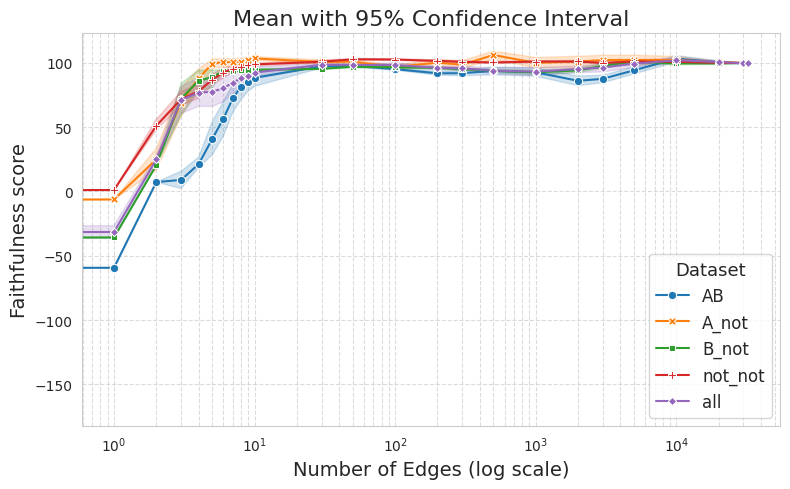

In [471]:
fsc_dicts = []
labels = ['AB','A_not','B_not','not_not','all']
all_fsc_dicts = []
for source_relation in labels:
    print(f"----------{source_relation}-------------")
    fsc_dicts = []
    for i,seed in enumerate(seeds):
        path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{source_relation}/falthfulness_score_{source_relation}.json'
        #print(f'{i} readng from {path}')
        with open(path,'r') as f:
            data = json.load(f)
        if None not in data.values():
            fsc_dicts.append(data)
        else:
            print(f'null in file:{path}')
        #print(len(data))
        #fsc_dicts.append(data)
    all_fsc_dicts.append(fsc_dicts)
save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/training_faithful_score.png'
plot_multiple_with_cnfiin(all_fsc_dicts, labels, save_path=save_path)

# test plot for faithful score

In [107]:
def plot_from_single_json(fdict, save_path=None):
    sns.set_style("whitegrid")

    df = pd.DataFrame({
        "key": [float(k) for k in fdict.keys()],
        "value": list(fdict.values())
    }).sort_values("key")

    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df,
        x="key",
        y="value",
        marker="o"
    )

    plt.xscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.7)
    plt.xlabel("Key")
    plt.ylabel("Value")
    plt.title("Value vs Key (log scale)")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")

    plt.show()

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_small/all/all_clm_42/AB/plot_falthfulness.png


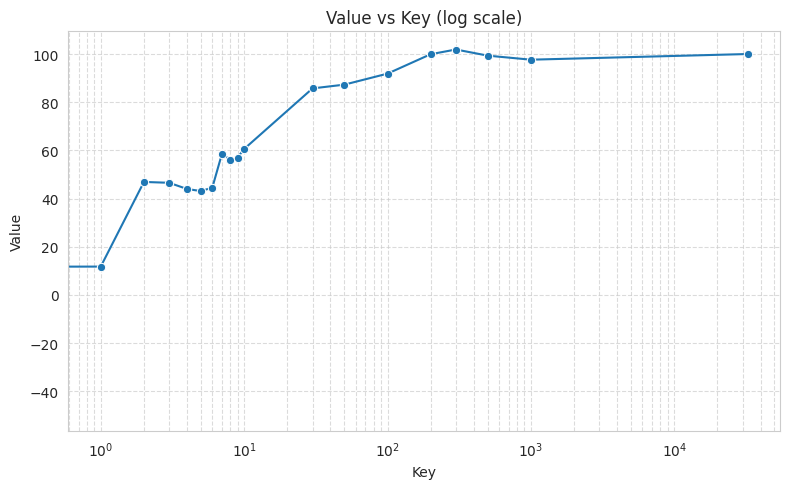

In [274]:
desired_relation = 'AB'
seed=42
path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
plot_path =  f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/plot_falthfulness.png'
with open(path,'r') as f:
    fdict = json.load(f)
plot_from_single_json(fdict, plot_path)

In [55]:

import seaborn as sns
import pandas as pd

import matplotlib.pyplot as plt

ALL_RELATIONS = ['AB','A_not','B_not', 'not_not', 'all', 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result', 'All_intersection', 'All_union', 'All_top']

palette = dict(zip(
    ALL_RELATIONS,
    sns.color_palette("tab10", n_colors=len(ALL_RELATIONS))
))

def plot_from_multiple_jsons(dict_list, source, labels=None, save_path=None, palette=None, label_header="dataset", vertical_line=None):
    sns.set_style("whitegrid")

    records = []
    for i, fdict in enumerate(dict_list):
        label = labels[i] if labels else f"Dataset {i+1}"
        for k, v in fdict.items():
            records.append({
                "key": float(k),
                "value": v,
                label_header: label
            })

    df = pd.DataFrame(records).sort_values("key")

    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df,
        x="key",
        y="value",
        hue=label_header,
        style=label_header,
        markers=True,
        dashes=False,
        palette=palette      # 🔑 fixed colors
    )
    
    if vertical_line is not None and isinstance(vertical_line, int):
        plt.axvline(x=vertical_line, color='black', linestyle='--', linewidth=1.5)
    elif vertical_line is not None and isinstance(vertical_line, list):
        for vl in vertical_line:
            plt.axvline(x=vl, color='black', linestyle='--', linewidth=1.5)
            
    plt.xscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.7)
    plt.xlabel("Number of Edges (log scale)", fontsize=28)
    plt.ylabel("Faithfulness score", fontsize=28)
    plt.title(f"Performance for {source} constructions", fontsize=28)
    #plt.legend(title="Dataset")

    # Set tick labels font
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    plt.legend(
        title=label_header,
        loc="lower right",
        fontsize=12,
        title_fontsize=16,
        frameon=True
    )

    plt.tight_layout()
    

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")

    plt.show()


Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_faithful_score_AB.png


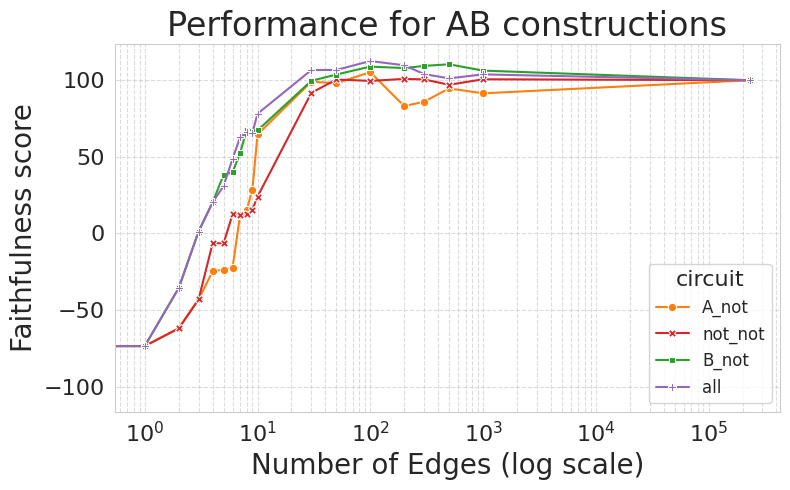

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_faithful_score_A_not.png


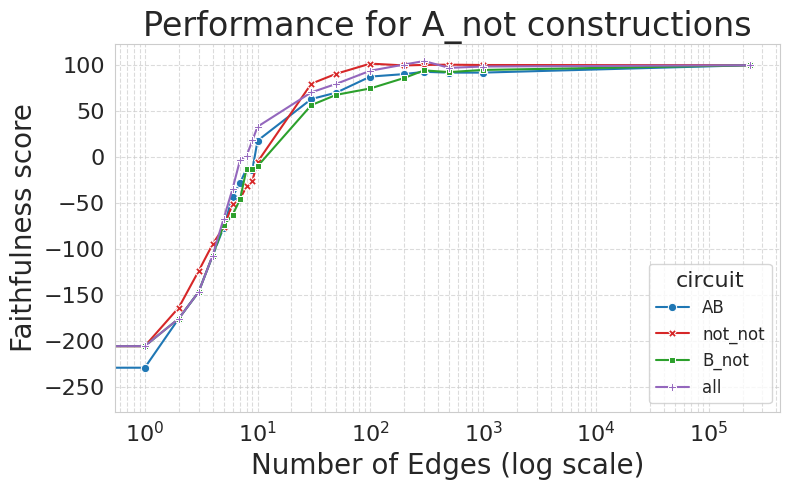

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_faithful_score_B_not.png


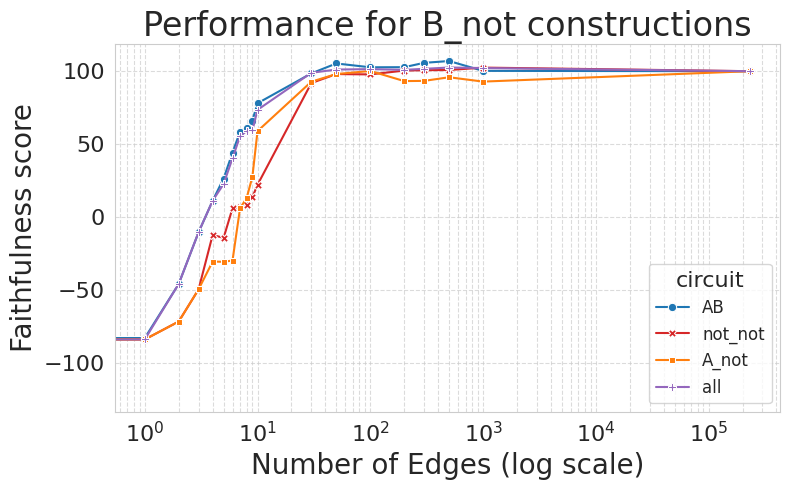

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_faithful_score_not_not.png


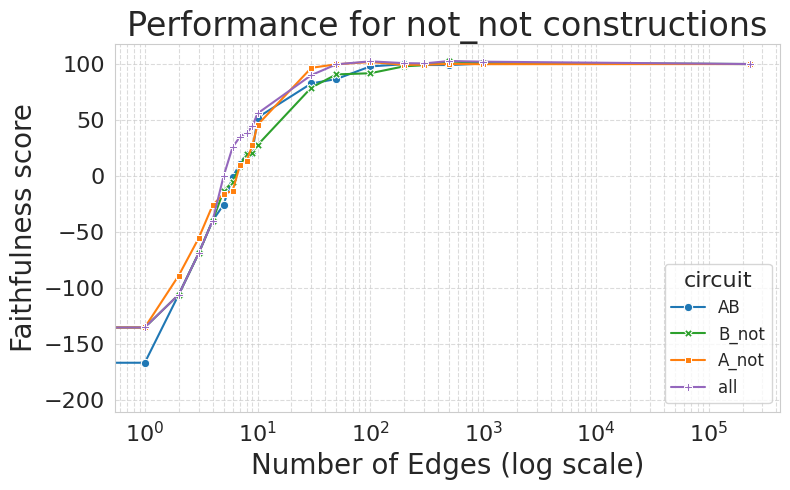

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_faithful_score_all.png


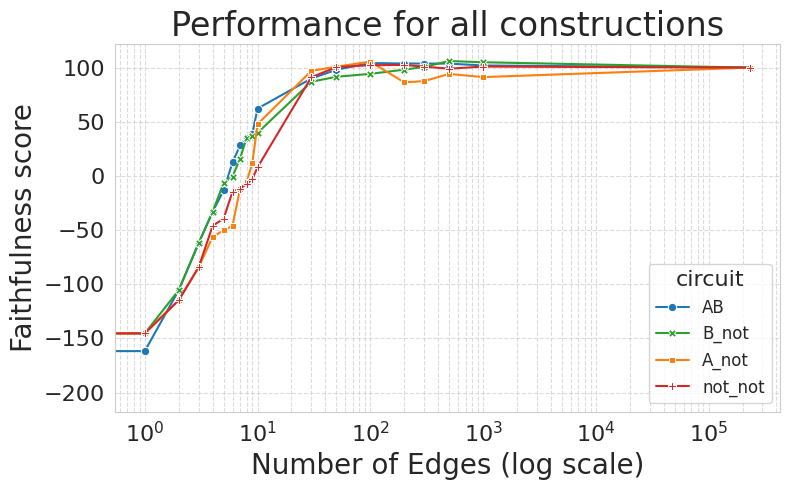

In [8]:
import json
import pandas as pd
desired_relations = ['AB','A_not','B_not', 'not_not', 'all']
source_relations = ['AB','A_not','B_not', 'not_not', 'all']#, 'L3_Contingency_Cause_Result']# 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result']
seed=42
model_mode_outer = 'clm_medium'
model_mode = 'clm'
for desired_relation  in desired_relations:
    dict_list = []
    labels = []
    for source_relation in source_relations :
        if source_relation == desired_relation:
            continue
        labels.append(source_relation)
        if source_relation[0]=='L':
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/clm/other_circuits/{source_relation}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        else:
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        with open(path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
    save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/by_dataset_performance/test_faithful_score_{desired_relation}.png'
    plot_from_multiple_jsons(dict_list, desired_relation, labels=labels, save_path=save_path, palette=palette, label_header="circuit")

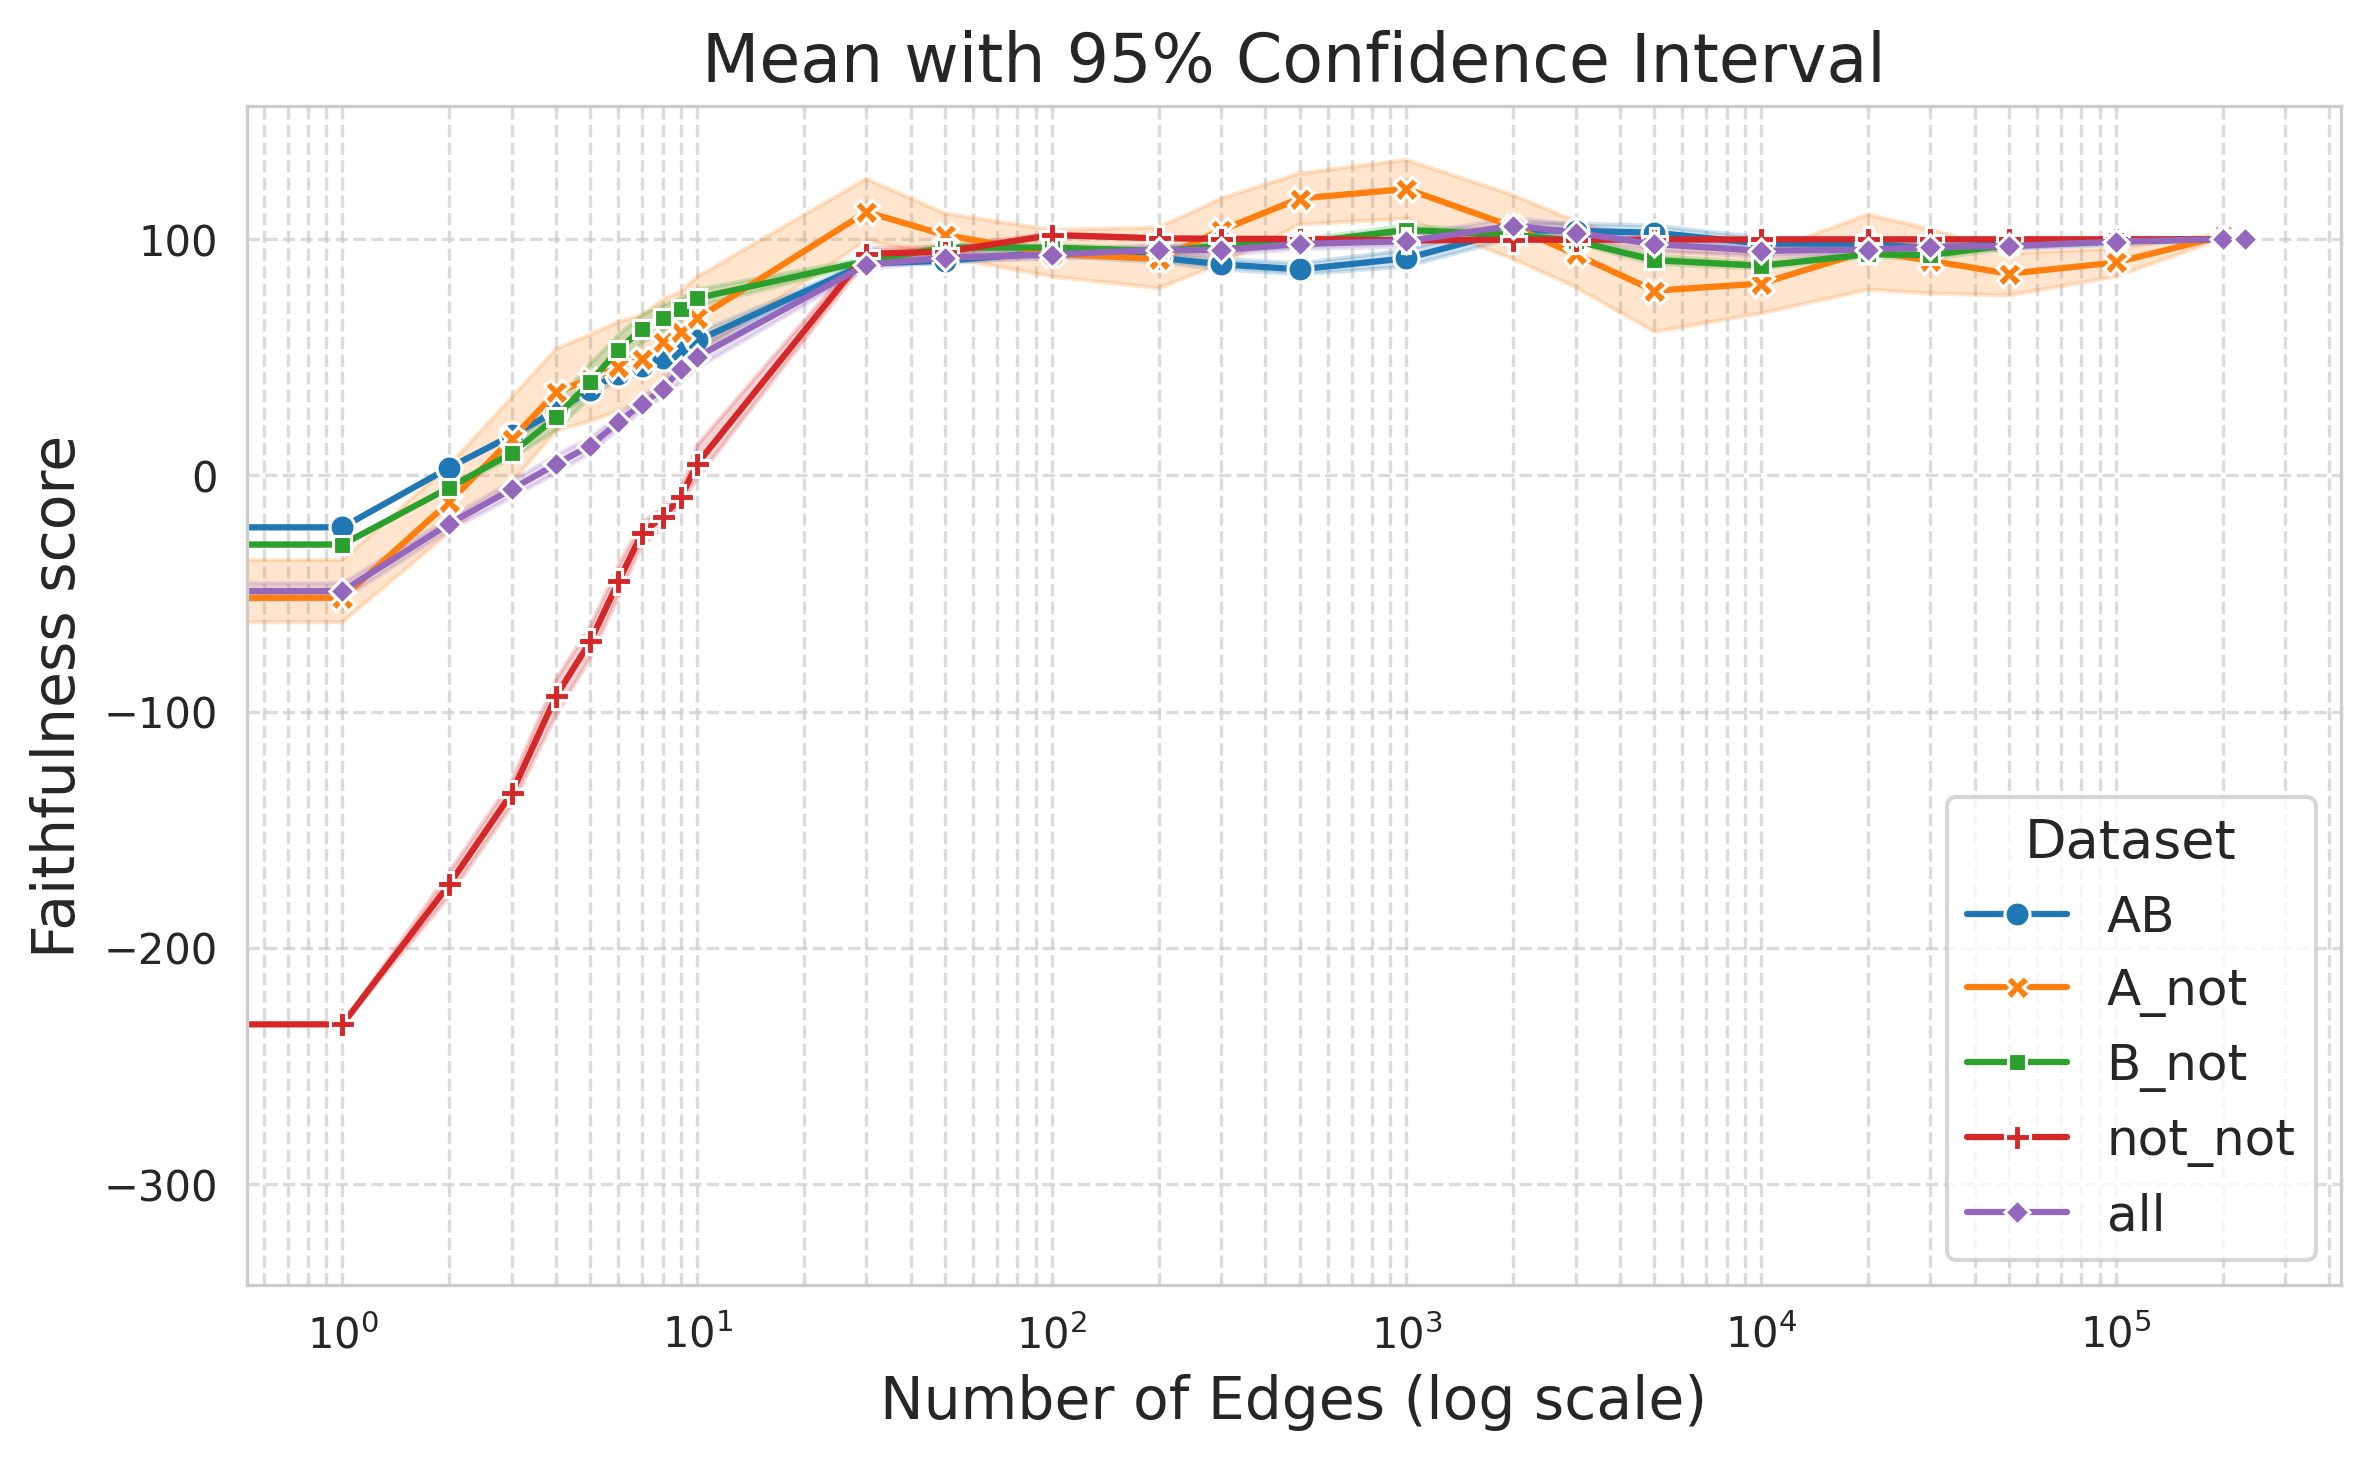

In [240]:
from IPython.display import Image, display

display(Image(filename="/srv/data1/abhidipbhatt/output/DC_exp/clm/plots/training_faithful_score.png"))

In [236]:
import shutil
import os

path =  f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/'
source_relation = 'not_not'
desired_relation = 'not_not'

source = os.path.join(path, f'falthfulness_score_{desired_relation}_Avg.json')
destination = os.path.join(path, f'falthfulness_score_{desired_relation}.json')
seeds = [42, 91, 532, 438, 793,
     156, 284, 907, 63, 419,
     712, 35, 668, 501, 229,
     874, 94, 360, 781, 147,
     590, 18, 946, 312, 655,
     87, 478, 821, 204, 739]
#os.makedirs(os.path.dirname(destination), exist_ok=True)

for seed in seeds:
    path =  f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode}_inv/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/'
    source = os.path.join(path, f'falthfulness_score_{desired_relation}_Avg.json')
    destination = os.path.join(path, f'falthfulness_score_{desired_relation}.json')
    try:
        shutil.move(source, destination)
        print(f"Success: File '{source}' moved and renamed to '{destination}' successfully.")
    except FileNotFoundError:
        print(f"Error: The source file '{source}' not found.")

Success: File '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_42/not_not/falthfulness_score_not_not_Avg.json' moved and renamed to '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_42/not_not/falthfulness_score_not_not.json' successfully.
Success: File '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_91/not_not/falthfulness_score_not_not_Avg.json' moved and renamed to '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_91/not_not/falthfulness_score_not_not.json' successfully.
Success: File '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_532/not_not/falthfulness_score_not_not_Avg.json' moved and renamed to '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_532/not_not/falthfulness_score_not_not.json' successfully.
Success: File '/srv/data1/abhidipbhatt/output/DC_exp/clm_inv/not_not/not_not_clm_438/not_not/falthfulness_score_not_not_Avg.json' moved and renamed to '/srv/data1/abhidipbha

# making the ALL-int circut
1. take top 1000 edges from all other circuits
2. check for intersection

In [620]:
edges = {}
model_mode_outer = 'clm_small_inv'
for source_relation in ['AB','A_not','B_not','not_not']:
    result_dir = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/'
    edge_names_file_raw = os.path.join(result_dir, f'top_1000_edges.json')
    with open(edge_names_file_raw,'r') as f:
        data = json.load(f)
    edges[source_relation] = data

In [621]:
len(edges['AB'])

1000

In [622]:
common_keys = set(edges['AB'].keys())
for k,d in edges.items():
    common_keys = common_keys.intersection(d.keys())


result1 = {
    key: max(d.get(key,0) for _,d in edges.items())
    for key in common_keys
}

folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_intersection/'
os.makedirs(folder, exist_ok=True)
filename = os.path.join(folder, 'top_edges.json')
with open(filename, 'w') as f:
    json.dump(result1,f)

In [623]:
len(result1)

57

In [635]:
num = len(result1)
result2 = defaultdict(int)
print(len(edges))
for k,d in edges.items():
    for key,v in d.items():
        result2[key]+=v
        
for key,v in result2.items():
    result2[key]= result2[key]/len(edges)
    
top_n = dict(sorted(result2.items(), key=lambda x: x[1], reverse=True)[:num])


folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_union/'
os.makedirs(folder, exist_ok=True)
filename = os.path.join(folder, 'top_edges.json')
print(filename)
with open(filename, 'w') as f:
    json.dump(top_n,f)

4
/srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/All_union/top_edges.json


In [636]:
source_relation ='all'
top_edges_all = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/top_1000_edges.json'
print(f'reading from {top_edges_all}')
with open(top_edges_all,'r') as f:
    all_circuit = json.load(f)
top_n = dict(sorted(all_circuit.items(), key=lambda x: x[1], reverse=True)[:num])
folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_top/'
os.makedirs(folder, exist_ok=True)
filename = os.path.join(folder, 'top_edges.json')
print(filename)
with open(filename, 'w') as f:
    json.dump(top_n,f)

reading from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_ALL_seeds/top_1000_edges.json
/srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/All_top/top_edges.json


reading /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/All_union/top_edges.json
reading /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/All_intersection/top_edges.json
reading /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/All_top/top_edges.json
saving at /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/circuir_overlap.png


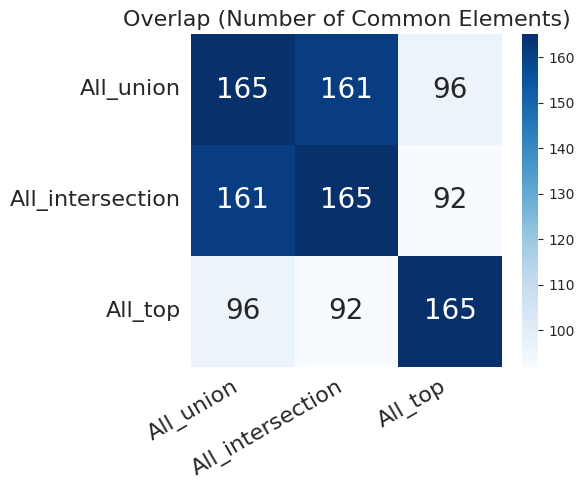

In [54]:
#intersection
import numpy as np
def overlap(sets1, sets2, set1_names, set2_names, cir1, cir2):
    
    n1 = len(sets1)
    n2 = len(sets2)
    overlap_matrix = np.zeros((n1, n2), dtype=int)

    # Compute intersection sizes
    for i in range(n1):
        for j in range(n2):
            overlap_matrix[i, j] = len(sets1[i] & sets2[j])

    # Plot heatmap
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        overlap_matrix,
        annot=True,           # show numbers inside cells
        fmt="d",              # integer formatting
        cmap="Blues",
        xticklabels=set2_names,
        yticklabels=set1_names,
        annot_kws={"size": 20}  # increase font size here
    )

    plt.title("Overlap (Number of Common Elements)",fontsize=16)
    #plt.xlabel(cir2,fontsize=16)
    #plt.ylabel(cir1, fontsize=16)
    plt.xticks(rotation=30, ha="right",fontsize=16)
    plt.yticks(rotation=360, ha="right",fontsize=16)
    plt.tight_layout()

    filename = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/All_approx/circuir_overlap.png'
    print(f'saving at {filename}')
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

sets = []
set_names = ['All_union', 'All_intersection','All_top']
model_mode_outer = 'clm_medium'
for cir in set_names:
    filename = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/{cir}/top_edges.json'
    print(f'reading {filename}')
    with open(filename, 'r') as f:
        data = json.load(f)
    set1 = set(data.keys())
    sets.append(set1)

overlap(sets, sets,set_names,set_names,'causation','causation')
    

165
Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/Circuit_vs_AB.png


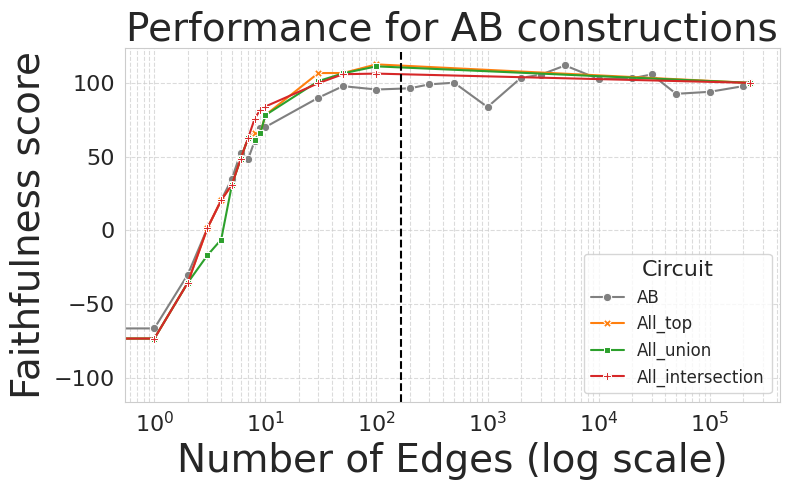

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/Circuit_vs_A_not.png


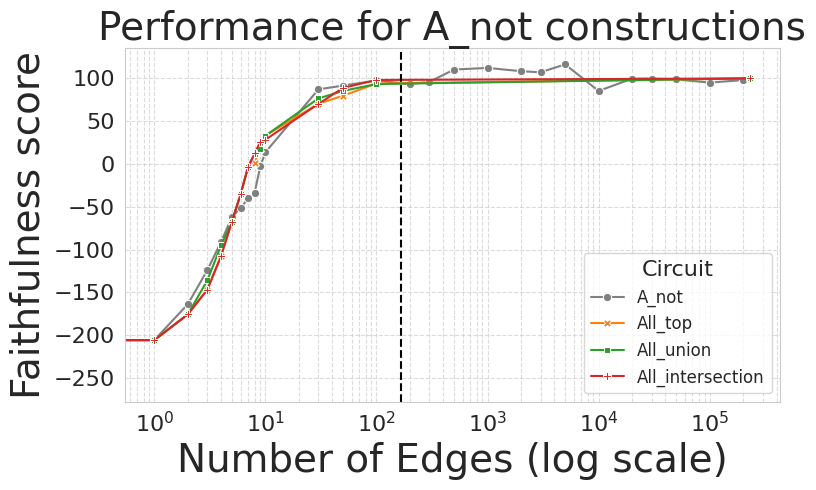

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/Circuit_vs_B_not.png


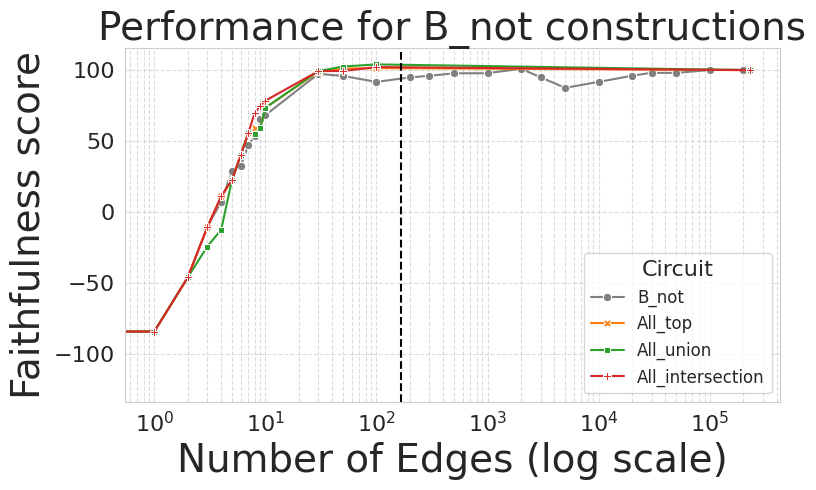

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/Circuit_vs_not_not.png


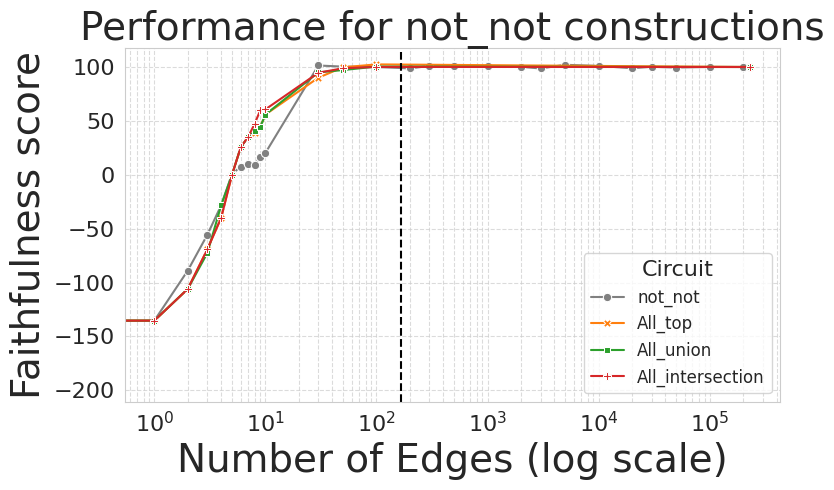

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx/Circuit_vs_all.png


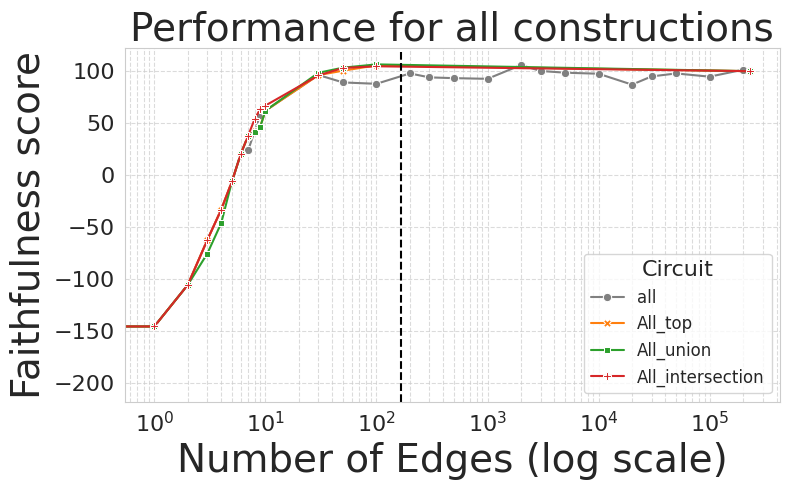

In [57]:
#model_mode_outer = 'clm_medium'
import os
desired_relations = ['AB','A_not','B_not', 'not_not', 'all']
source_relations = ['All_top','All_union','All_intersection']#, 'L3_Contingency_Cause_Result']# 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result']
seed=42
model_mode_outer = 'clm_medium'

folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_intersection/'
filename = os.path.join(folder, 'top_edges.json')
with open(filename, 'r') as f:
    edges = json.load(f)
vertical_line = len(edges)
print(vertical_line)
for desired_relation  in desired_relations:
    dict_list = []
    labels = []

    self_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{desired_relation}/{desired_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
    with open(self_path,'r') as f:
        fdict = json.load(f)
    dict_list.append(fdict)
    labels.append(desired_relation)
    
    for source_relation in source_relations :
        labels.append(source_relation)
        if source_relation[0]=='A':
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/{source_relation}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        else:
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        with open(path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
    #print(labels)
    label_header='Circuit'
    palette_local = dict(zip(
        labels,
        sns.color_palette("tab10", n_colors=len(labels))
    ))
    #print(palette_local)
    palette_local[desired_relation] = 'gray'    
    save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/All_approx/{label_header}_vs_{desired_relation}.png'
    plot_from_multiple_jsons(dict_list, desired_relation, labels=labels, save_path=save_path, palette=palette_local, label_header='Circuit',vertical_line=vertical_line)

# random baseline circuits
- for each edge file that you saved, instead of taking top-1000 take randomly 1000 (for different seed)
- run the patching on those and plot

In [481]:
import os
import json
import random

source_relation= 'all'
desired_relation = 'all'
model_mode='clm'
model_mode_outer = model_mode+"_small"
filtered = True
inverse = True
if inverse:
    model_mode_outer = model_mode_outer+'_inv'
    
seeds = [42, 91, 532, 438, 793,
     156, 284, 907, 63, 419,
     712, 35, 668, 501, 229,
     874, 94, 360, 781, 147,
     590, 18, 946, 312, 655,
     87, 478, 821, 204, 739]



In [482]:
result_dir = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_random_circuits/'
dicts = []

for i,seed in enumerate(seeds):
    random.seed(seed)
    path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/top_edge_names_raw_{desired_relation}.json'
    print(f'{i} readng from {path}')
    with open(path,'r') as f:
        data = json.load(f)
        #print(len(data))
    sampled_items = random.sample(list(data.items()), 1000)
    new_dict = dict(sampled_items)
    dicts.append(new_dict)


os.makedirs(result_dir, exist_ok=True)
for i,seed in enumerate(seeds):
    edge_names_file_raw = os.path.join(result_dir, f'rand_1000_edges_seed_{seed}.json')
    ran = dicts[i]
    with open(edge_names_file_raw, 'w') as f:
        json.dump(ran, f, indent=4) #top_1000_edges_raw
        print(f'Saved top edge names to {edge_names_file_raw}')

0 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_42/all/top_edge_names_raw_all.json
1 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_91/all/top_edge_names_raw_all.json
2 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_532/all/top_edge_names_raw_all.json
3 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_438/all/top_edge_names_raw_all.json
4 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_793/all/top_edge_names_raw_all.json
5 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_156/all/top_edge_names_raw_all.json
6 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_284/all/top_edge_names_raw_all.json
7 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_907/all/top_edge_names_raw_all.json
8 readng from /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/all/all_clm_63/all/top_e

In [10]:
seeds = [42, 91, 532, 438, 793,
     156, 284, 907, 63, 419,
     712, 35, 668, 501, 229,
     874, 94, 360, 781, 147,
     590, 18, 946, 312, 655,
     87, 478, 821, 204, 739]
#model_mode_outer = 'clm_small'
def read_random_op(desired_relation, seeds, label_header="dataset"):
    dict_list = []
    for seed in seeds:
        path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/all/all_clm_random_circuits/{desired_relation}/{seed}/falthfulness_score_{desired_relation}.json'
        with open(path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
    df = pd.DataFrame(dict_list)
    df_long = df.melt(var_name="key", value_name="value")
    df_long["key"] = df_long["key"].astype(float)
    df_long[label_header] = 'random'
    return df_long
        #all_data.append(df_long)

In [25]:
ALL_RELATIONS = ['AB','A_not','B_not', 'not_not', 'all', 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result', 'All_intersection', 'All_union', 'All_top', 'random']
palette = dict(zip(
    ALL_RELATIONS,
    sns.color_palette("tab10", n_colors=len(ALL_RELATIONS))
))

# Override the color for "random"
palette['random'] = 'gray'

def plot_with_random_baseline(dict_list, random_df, source, labels=None, save_path=None, palette=None, label_header="dataset"):
    sns.set_style("whitegrid")

    records = []
    for i, fdict in enumerate(dict_list):
        label = labels[i] if labels else f"Dataset {i+1}"
        for k, v in fdict.items():
            records.append({
                "key": float(k),
                "value": v,
                label_header: label
            })

    df_tmp = pd.DataFrame(records).sort_values("key")
    df = pd.concat([df_tmp, random_df], axis=0)
    #print(df)

    plt.figure(figsize=(8, 5))
    sns.lineplot(
        data=df,
        x="key",
        y="value",
        hue=label_header,
        style=label_header,
        markers=True,
        dashes=False,
        estimator="mean",
        errorbar=("ci", 95),
        palette=palette      # 🔑 fixed colors
    )

    plt.xscale("log")
    plt.grid(True, which="both", linestyle="--", alpha=0.7)
    plt.xlabel("Number of Edges (log scale)", fontsize=28)
    plt.ylabel("Faithfulness score", fontsize=28)
    plt.title(f"Performance for {source} constructions", fontsize=28)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    #plt.legend(title="Dataset")
    plt.legend(
        title=label_header,
        loc="lower right",
        fontsize=14,
        title_fontsize=12,
        frameon=True
    )

    plt.tight_layout()
    

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")

    plt.show()

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_AB.png


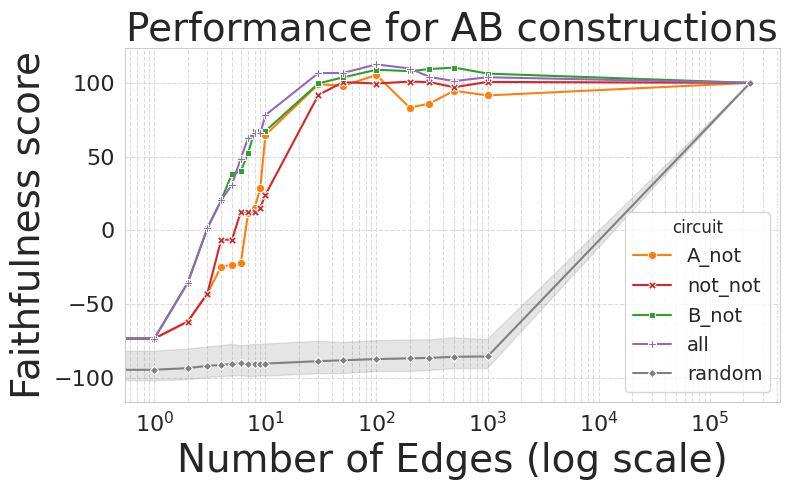

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_A_not.png


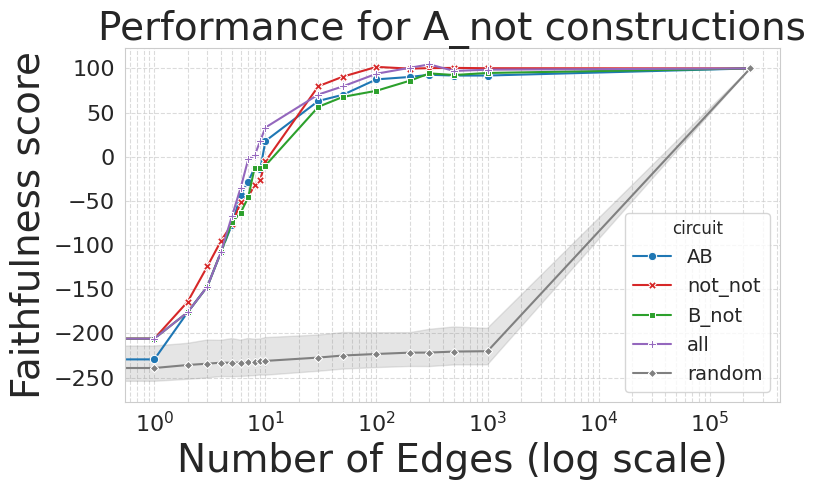

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_B_not.png


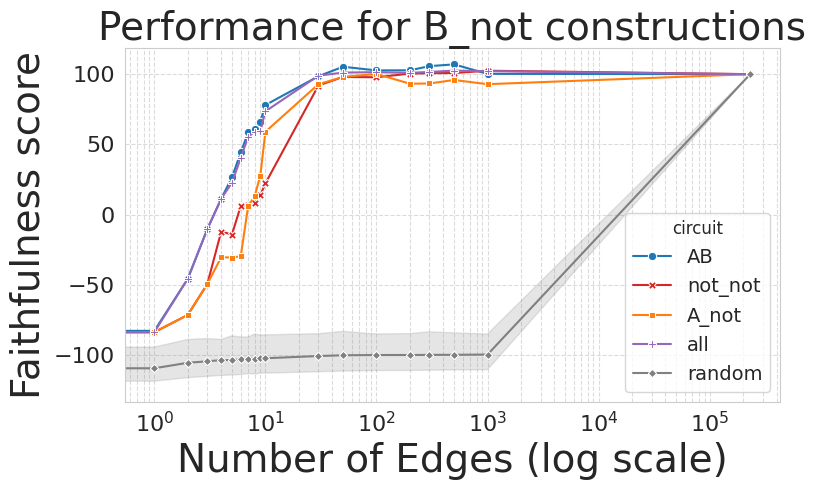

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_not_not.png


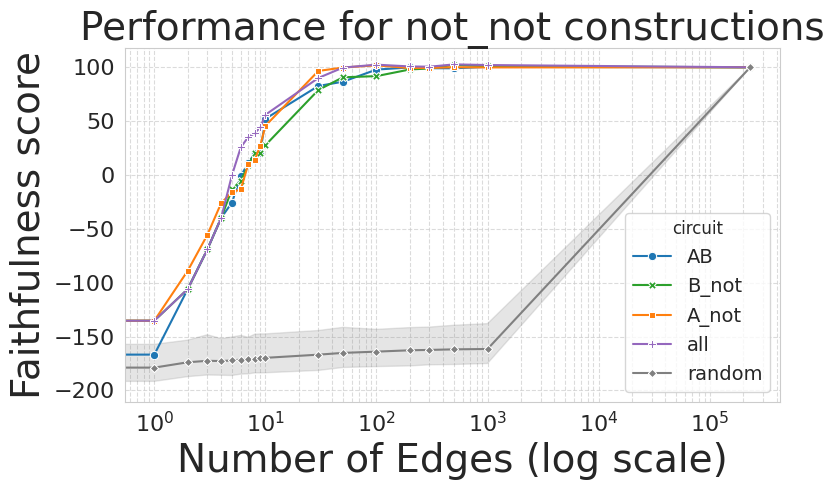

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_all.png


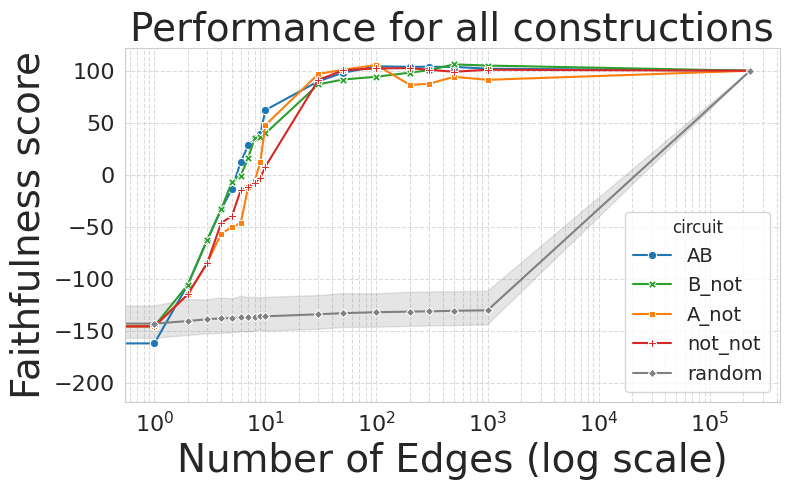

In [27]:
import json
import pandas as pd
desired_relations = ['AB','A_not','B_not', 'not_not', 'all']
source_relations = ['AB','A_not','B_not', 'not_not', 'all']#, 'L3_Contingency_Cause_Result']# 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result']
seed=42
model_mode_outer = 'clm_medium'
model_mode = 'clm'
for desired_relation  in desired_relations:
    dict_list = []
    labels = []
    RB_DF = read_random_op(desired_relation,seeds,'circuit')
    
    for source_relation in source_relations :
        if source_relation == desired_relation:
            continue
        labels.append(source_relation)
        if source_relation[0]=='L':
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/clm/other_circuits/{source_relation}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        else:
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        with open(path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
        #test_fscoreRB
    save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/by_dataset_performance/test_fscoreRB_{desired_relation}.png'
    plot_with_random_baseline(dict_list,RB_DF, desired_relation, labels=labels, save_path=save_path, palette=palette, label_header="circuit")

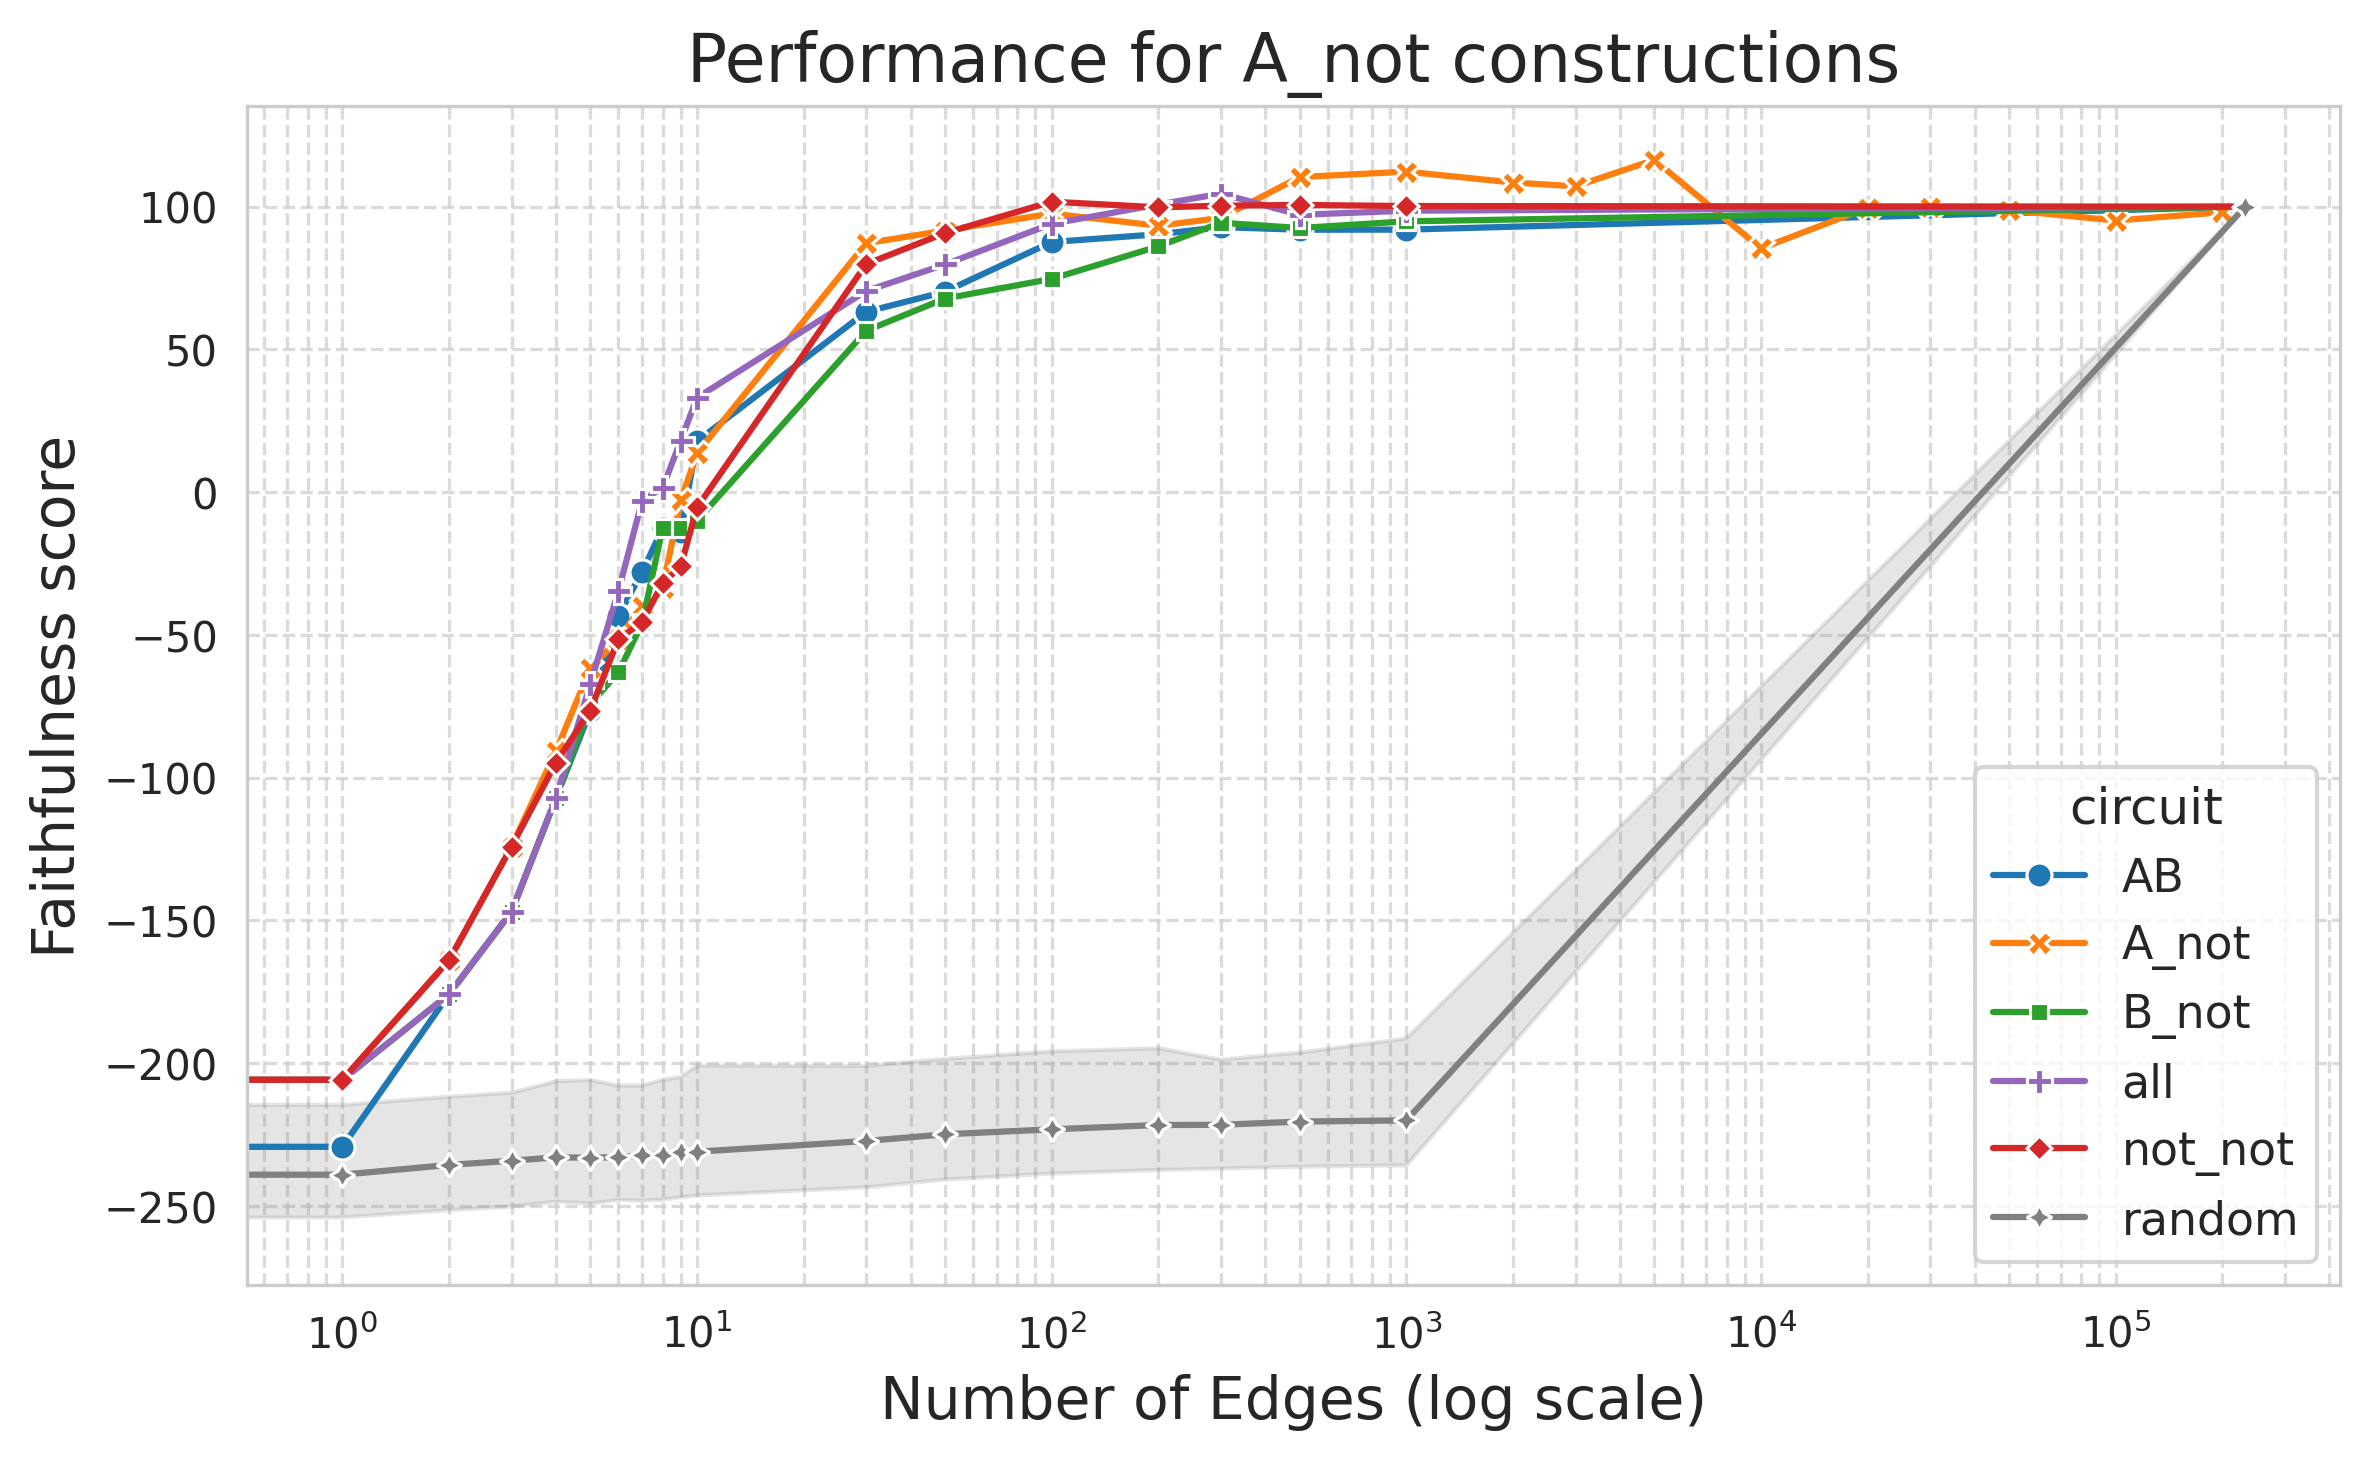

In [19]:
from IPython.display import Image, display

display(Image(filename="/srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/by_dataset_performance/test_fscoreRB_A_not.png"))

/srv/data1/abhidipbhatt/output/DC_exp/clm_medium_inv/plots/circuir_overlap_cau_anti.png


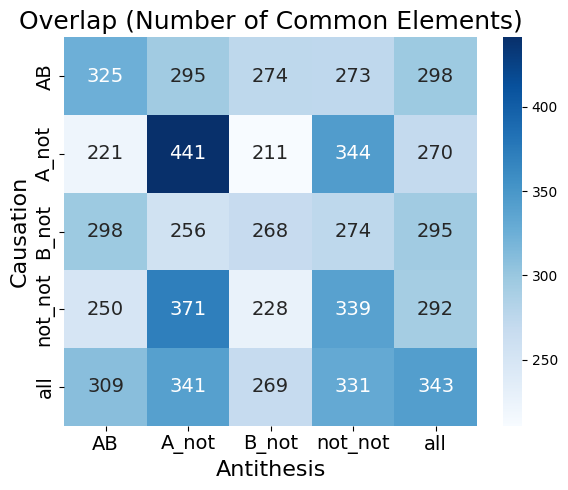

'\nsets, set_names = get_circuit_info(model=model, inverse=inverse)\nif inverse:\n    cir = cir2\nelse:\n    cir = cir1\noverlap(sets,sets,set_names,set_names,cir,cir)\n'

In [17]:
# intersection:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json

model = 'medium'
model_mode = 'clm'
inverse = True

outer_folder= model_mode+'_'+model
if inverse:
    outer_folder = outer_folder+"_inv"
    
def get_circuit_info(model='medium', inverse=False):
    model_mode = 'clm'
    set_names = ["AB", "A_not", "B_not", "not_not", "all"]
    outer_folder= model_mode+'_'+model
    if inverse:
        outer_folder = outer_folder+"_inv"

    sets = []
    for source_relation in set_names:
        circuit_file = f'/srv/data1/abhidipbhatt/output/DC_exp/{outer_folder}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/top_1000_edges.json' 
        with open(circuit_file, 'r') as f:
            top_edges = json.load(f)
        keys = set(top_edges.keys())
        sets.append(keys)
    return sets, set_names


def get_cross_circuit_info(model='medium', inverse=False):
    model_mode = 'clm'
    set_names = ["AB", "A_not", "B_not", "not_not", "all"]
    outer_folder= model_mode+'_'+model
    
    outer_folder2 = outer_folder+"_inv"

    sets = []
    for source_relation in set_names:
        circuit_file = f'/srv/data1/abhidipbhatt/output/DC_exp/{outer_folder}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/top_1000_edges.json' 
        with open(circuit_file, 'r') as f:
            top_edges = json.load(f)
        keys = set(top_edges.keys())
        sets.append(keys)
    inv_sets = []
    for source_relation in set_names:
        circuit_file = f'/srv/data1/abhidipbhatt/output/DC_exp/{outer_folder2}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/top_1000_edges.json' 
        with open(circuit_file, 'r') as f:
            top_edges = json.load(f)
        keys = set(top_edges.keys())
        inv_sets.append(keys)
        
    return sets,inv_sets, set_names


# Names of the sets


def overlap(sets1, sets2, set1_names, set2_names, cir1, cir2):
    
    n1 = len(sets1)
    n2 = len(sets2)
    overlap_matrix = np.zeros((n1, n2), dtype=int)

    # Compute intersection sizes
    for i in range(n1):
        for j in range(n2):
            overlap_matrix[i, j] = len(sets1[i] & sets2[j])

    # Plot heatmap
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        overlap_matrix,
        annot=True,           # show numbers inside cells
        fmt="d",              # integer formatting
        cmap="Blues",
        xticklabels=set2_names,
        yticklabels=set1_names,
        annot_kws={"size": 14}  # increase font size here
    )

    plt.title("Overlap (Number of Common Elements)",fontsize=18)
    plt.xlabel(cir2,fontsize=16)
    plt.ylabel(cir1, fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.tight_layout()

    filename = f'/srv/data1/abhidipbhatt/output/DC_exp/{outer_folder}/plots/circuir_overlap_cau_anti.png'#circuir_overlap_cau_anti.png circuir_overlap
    print(filename)
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

cir1 = 'Causation'
cir2= 'Antithesis'
# Example sets

sets,inv_sets, set_names = get_cross_circuit_info(model=model, inverse=inverse)#get_circuit_info(model=model, inverse=inverse)
overlap(sets,inv_sets,set_names,set_names,cir1,cir2)
'''
sets, set_names = get_circuit_info(model=model, inverse=inverse)
if inverse:
    cir = cir2
else:
    cir = cir1
overlap(sets,sets,set_names,set_names,cir,cir)
'''

# intersection between ante and causation circuits

In [513]:
edges = {}
#model_mode_outer = 'clm_medium_inv'
source_relation = 'all'#'AB','A_not','B_not','not_not'
for model_mode_outer in ['clm_medium_inv', 'clm_medium']:
    result_dir = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/'
    edge_names_file_raw = os.path.join(result_dir, f'top_1000_edges.json')
    with open(edge_names_file_raw,'r') as f:
        data = json.load(f)
    edges[model_mode_outer] = data

common_keys = set(edges[model_mode_outer].keys())
for k,d in edges.items():
    common_keys = common_keys.intersection(d.keys())
    
result1 = {
    key: max(d.get(key,0) for _,d in edges.items())
    for key in common_keys
}

for model_mode_outer in ['clm_medium_inv', 'clm_medium']:
    folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_intersection_causation_ante/'
    os.makedirs(folder, exist_ok=True)
    filename = os.path.join(folder, 'top_edges.json')
    with open(filename, 'w') as f:
        json.dump(result1,f)

print(len(result1))

343


In [514]:
for model_mode_outer in ['clm_medium_inv', 'clm_medium']:
    top_edges_all = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/top_1000_edges.json'
    print(f'reading from {top_edges_all}')
    with open(top_edges_all,'r') as f:
        all_circuit = json.load(f)
    top_n = dict(sorted(result2.items(), key=lambda x: x[1], reverse=True)[:num])
    folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/All_top_causation_ante/'
    os.makedirs(folder, exist_ok=True)
    filename = os.path.join(folder, 'top_edges.json')
    print(f'writing to {filename}')
    with open(filename, 'w') as f:
        json.dump(top_n,f)

reading from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium_inv/all/all_clm_ALL_seeds/top_1000_edges.json
writing to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium_inv/All_approx/All_top_causation_ante/top_edges.json
reading from /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/all/all_clm_ALL_seeds/top_1000_edges.json
writing to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/All_top_causation_ante/top_edges.json


Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium_inv/plots/All_approx_caus_ante/Circuit_vs_all.png


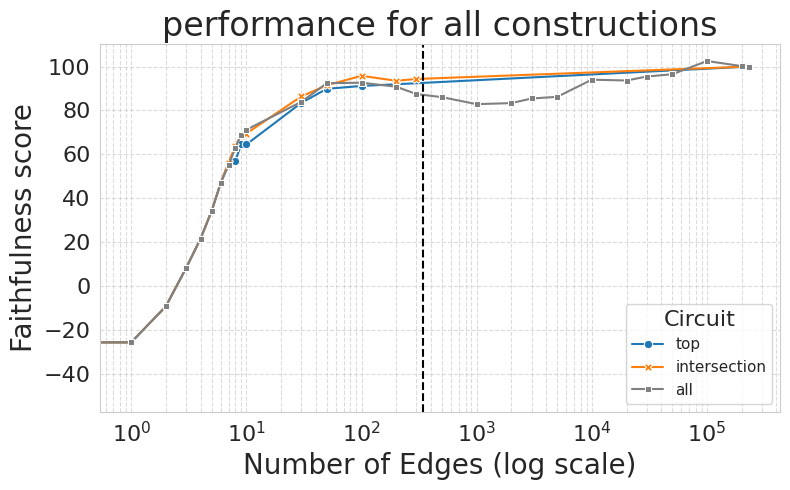

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/All_approx_caus_ante/Circuit_vs_all.png


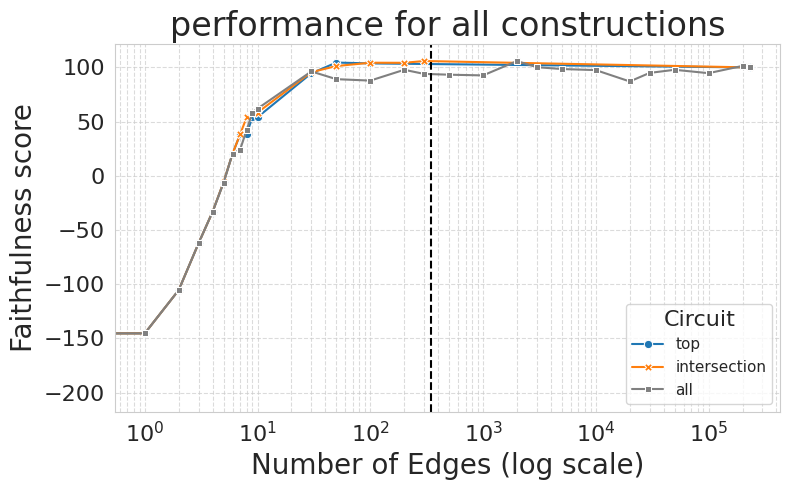

In [589]:
ALL_RELATIONS = ['all','All_top_causation_ante', 'All_intersection_causation_ante']

model_mode_outer_list = ['clm_medium_inv', 'clm_medium']
#desired_relations = ['AB','A_not','B_not', 'not_not', 'all']
source_relations = ['All_top_causation_ante','All_intersection_causation_ante','all']#, 'L3_Contingency_Cause_Result']# 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result']
source_labels = ['top','intersection','all']
seed=42
desired_relation = 'all'
#model_mode_outer = 'clm_medium'
for model_mode_outer  in model_mode_outer_list:
    dict_list = []
    labels = []
    for sl,source_relation in zip(source_labels, source_relations):
        dir_ = 'antethesis' if 'inv' in model_mode_outer  else 'causation'
        label = sl #f'{dir_}+{sl}'
            
        labels.append(label)
        if source_relation[0]=='A':
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/{source_relation}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        else:
            path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        with open(path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
    
    palette2 = dict(zip(
        labels,
        sns.color_palette("tab10", n_colors=len(ALL_RELATIONS))
    ))
    palette2[desired_relation] = 'gray'
    label_header='Circuit'
    save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/All_approx_caus_ante/{label_header}_vs_{desired_relation}.png'
    plot_from_multiple_jsons(dict_list, desired_relation, labels=labels, save_path=save_path, palette=palette2, label_header='Circuit',vertical_line=343)

## RQ3: Existence of hierarchical organization of discourse circuits

In [615]:
edges = []
#model_mode_outer = 'clm_medium_inv'
source_relation_list = ['all','AB','A_not','B_not','not_not']
msize= 'small'
model_list = [f'clm_{msize}_inv', f'clm_{msize}']
for model_mode_outer in model_list:
    for source_relation in source_relation_list:
        result_dir = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_ALL_seeds/'
        edge_names_file_raw = os.path.join(result_dir, f'top_1000_edges.json')
        with open(edge_names_file_raw,'r') as f:
            data = json.load(f)
        edges.append(data)

common_keys = set(edges[0].keys())
for d in edges:
    common_keys = common_keys.intersection(d.keys())
    
result1 = {
    key: max(d.get(key,0) for d in edges)
    for key in common_keys
}

for model_mode_outer in model_list:
    folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/SUPER_All_intersection/'
    os.makedirs(folder, exist_ok=True)
    filename = os.path.join(folder, 'top_edges.json')
    print(f'saved at {filename}')
    with open(filename, 'w') as f:
        json.dump(result1,f)

print(len(result1))

saved at /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/SUPER_All_intersection/top_edges.json
saved at /srv/data1/abhidipbhatt/output/DC_exp/clm_small/All_approx/SUPER_All_intersection/top_edges.json
23


In [616]:
num = len(result1)
result2 = defaultdict(int)
print(num)
for d in edges:
    for key,v in d.items():
        result2[key]+=v
        
for key,v in result2.items():
    result2[key]= result2[key]/len(edges)
    
top_n = dict(sorted(result2.items(), key=lambda x: x[1], reverse=True)[:num])

for model_mode_outer in model_list:
    folder = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/SUPER_All_union/'
    os.makedirs(folder, exist_ok=True)
    filename = os.path.join(folder, 'top_edges.json')
    print(f'saved at {filename}')
    with open(filename, 'w') as f:
        json.dump(top_n,f)

23
saved at /srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/SUPER_All_union/top_edges.json
saved at /srv/data1/abhidipbhatt/output/DC_exp/clm_small/All_approx/SUPER_All_union/top_edges.json


Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/SUP_All/Sup_cir_vs_AB.png


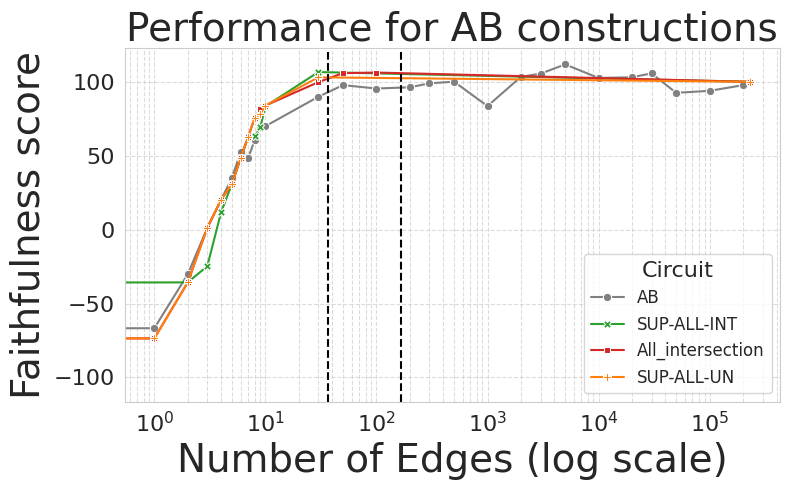

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/SUP_All/Sup_cir_vs_A_not.png


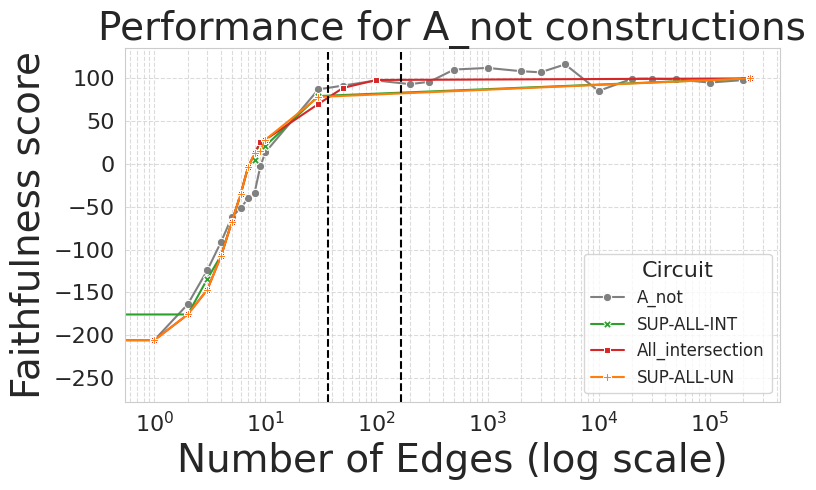

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/SUP_All/Sup_cir_vs_B_not.png


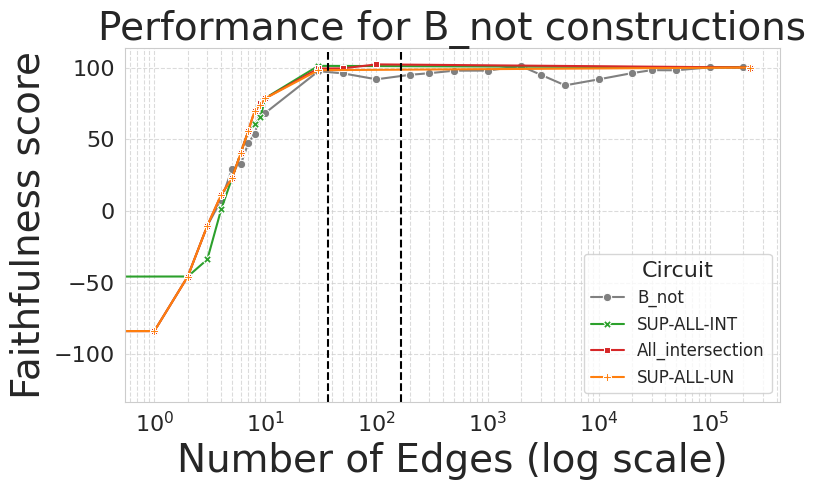

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/SUP_All/Sup_cir_vs_not_not.png


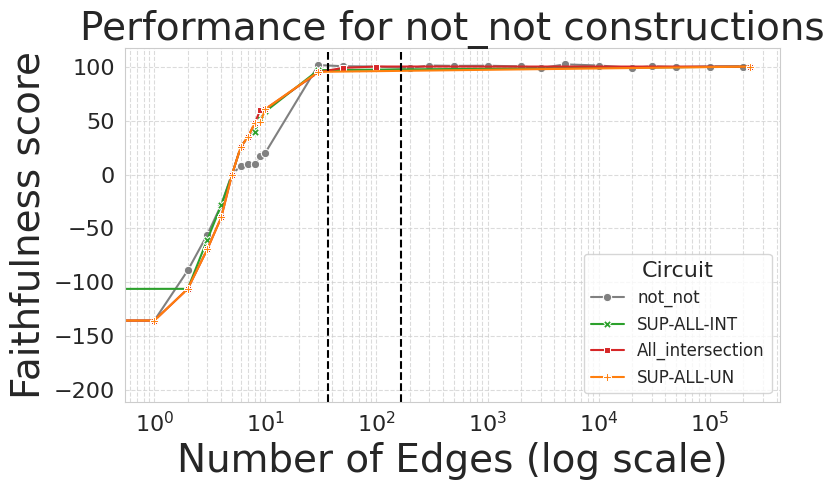

Figure saved to /srv/data1/abhidipbhatt/output/DC_exp/clm_medium/plots/SUP_All/Sup_cir_vs_all.png


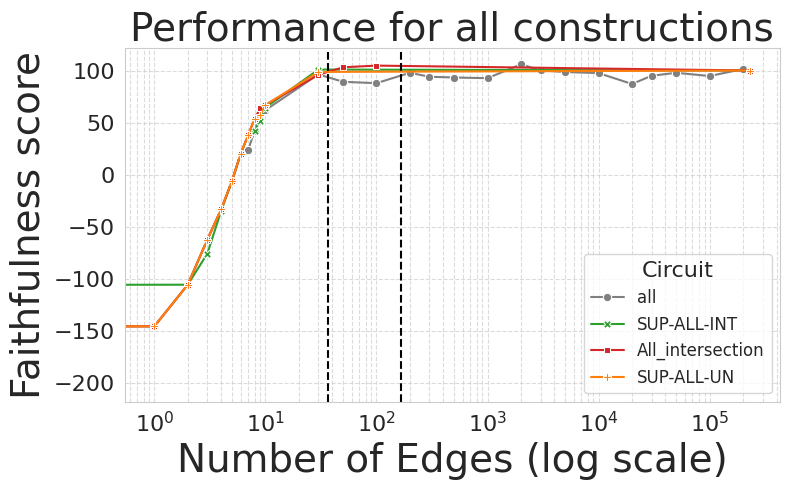

In [58]:
#ALL_RELATIONS = ['SUPER_All_union', 'SUPER_All_intersection','All_intersection']

model_mode_outer_list = ['clm_medium']#, 'clm_medium_inv']
#desired_relations = ['AB','A_not','B_not', 'not_not', 'all']
source_relations = ['SUPER_All_union', 'SUPER_All_intersection','All_intersection']#, 'L3_Contingency_Cause_Result']# 'L1_Comparison', 'L1_Contingency', 'L3_Comparison_Contrast', 'L3_Contingency_Cause_Reason', 'L3_Contingency_Cause_Result']
source_labels = ['SUP-ALL-UN','SUP-ALL-INT', 'All_intersection']
seed=42
desired_relation_list = ['AB', 'A_not', 'B_not', 'not_not', 'all']
#model_mode_outer = 'clm_medium'
for desired_relation in desired_relation_list:
    for model_mode_outer  in model_mode_outer_list:
        dict_list = []
        labels = []
    
        self_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{desired_relation}/{desired_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
        with open(self_path,'r') as f:
            fdict = json.load(f)
        dict_list.append(fdict)
        labels.append(desired_relation)
    
        for sl,source_relation in zip(source_labels, source_relations):
            dir_ = 'antethesis' if 'inv' in model_mode_outer else 'causation'
            label = sl #f'{dir_}+{sl}'
            
            labels.append(label)
            if source_relation[0]=='A' or source_relation[0]=='S':
                path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/All_approx/{source_relation}/{desired_relation}/falthfulness_score_{desired_relation}.json'
            else:
                path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
            with open(path,'r') as f:
                fdict = json.load(f)
            dict_list.append(fdict)

        #print(labels)
        palette_local = dict(zip(
            labels,
            sns.color_palette("tab10", n_colors=len(labels))
        ))
        palette_local[desired_relation] = 'gray'
        label_header='Sup_cir'
        save_path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/plots/SUP_All/{label_header}_vs_{desired_relation}.png'
        plot_from_multiple_jsons(dict_list, desired_relation, labels=labels, save_path=save_path, palette=palette_local, label_header='Circuit',vertical_line=[37,165])

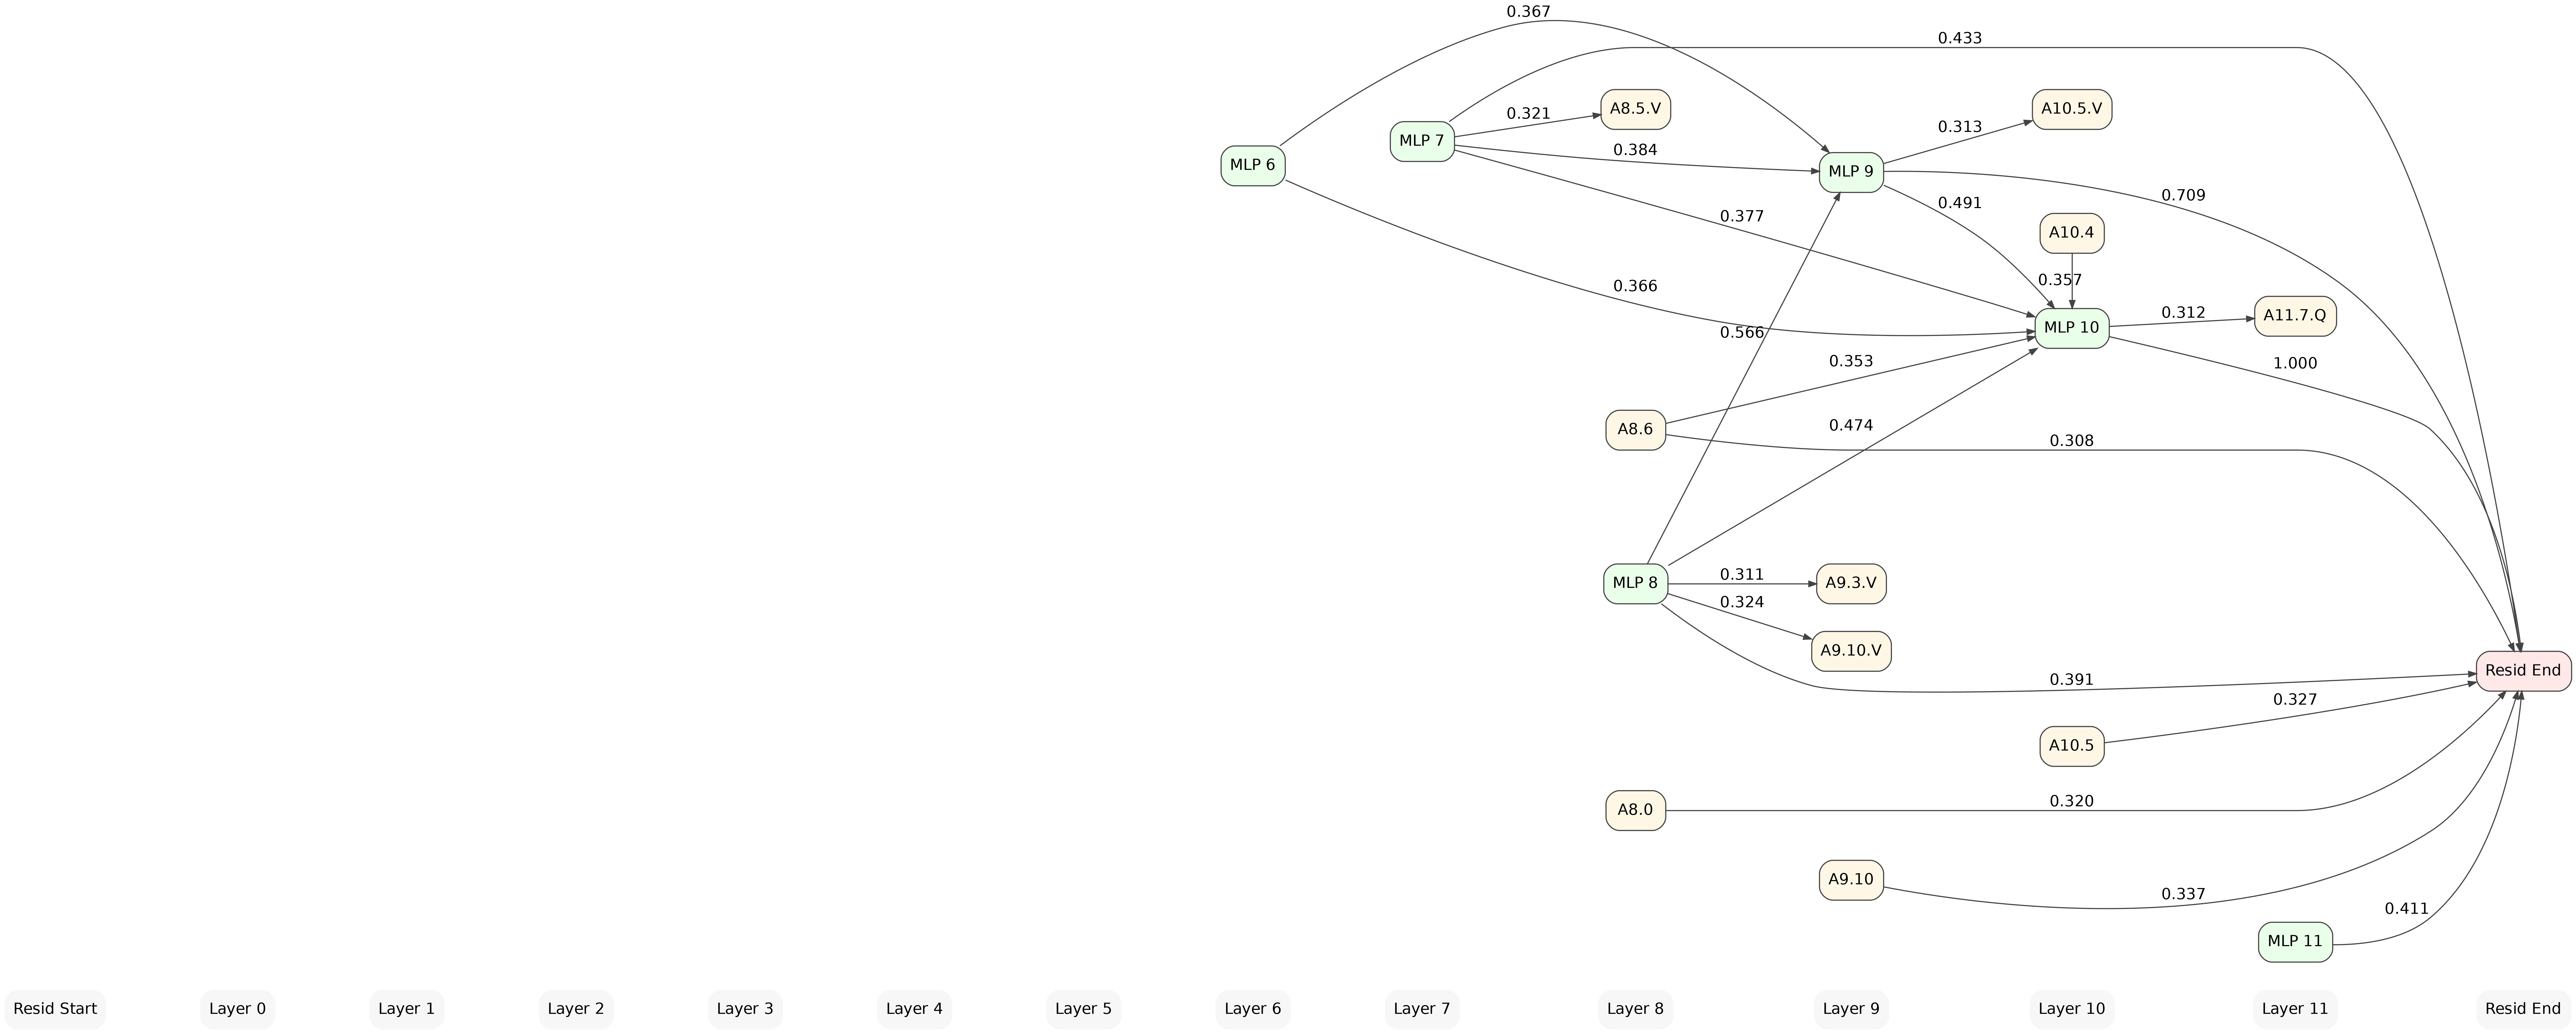

In [618]:
from IPython.display import Image, display

display(Image(filename="/srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/SUPER_All_intersection/top_edges.optionA.png"))

In [630]:
from IPython.display import Image, display

display(Image(filename="/srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/SUPER_All_intersection/top_edges.optionA.png"))

In [645]:
# get %faithful score vs circuit size
model_mode_outer = 'clm_medium'
source_relation = 'ALL'
#desired_relation=
path = '/srv/data1/abhidipbhatt/output/DC_exp/clm_medium/All_approx/All_intersection/all/falthfulness_score_all.json'
#path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'

with open(path,'r') as f:
    data = json.load(f)
print(data)

{'0': -202.0845051506313, '1': -145.35386870595943, '2': -105.43867521076986, '3': -62.207933643622695, '4': -33.06157346655075, '5': -5.851416202772699, '6': 20.35008790421858, '7': 38.13644305317107, '8': 53.92501331258448, '9': 63.786962944628065, '10': 66.93684946507783, '30': 95.89935399394646, '50': 103.08963880879448, '100': 104.71043036022185, '231877': 100.0}


In [660]:
model_mode_outer = 'clm_medium'
source_relation = 'all'
desired_relation='all'
path = '/srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/All_intersection/all/falthfulness_score_all.json'
#path = f'/srv/data1/abhidipbhatt/output/DC_exp/{model_mode_outer}/{source_relation}/{source_relation}_{model_mode}_{seed}/{desired_relation}/falthfulness_score_{desired_relation}.json'
print(path)
with open(path,'r') as f:
    data = json.load(f)
print(data)

/srv/data1/abhidipbhatt/output/DC_exp/clm_small_inv/All_approx/All_intersection/all/falthfulness_score_all.json
{'0': -112.16665272187498, '1': -20.491109849156913, '2': 34.940228271294835, '3': 32.67255789610478, '4': 32.15818793662775, '5': 26.221271998403374, '6': 37.42477724431532, '7': 49.63292066639885, '8': 69.81008973918492, '9': 84.40158349537973, '10': 85.1511407729687, '30': 93.93710127538472, '50': 95.21441452347086, '32491': 100.0}


In [662]:
from transformers import TrainingArguments
import torch
path = '/srv/data1/abhidipbhatt/models/GPT2/gpt2-medium-FT_32B/training_args.bin'
# Load using torch.load
training_args = torch.load(path,weights_only=False)

# training_args is a TrainingArguments object
print(training_args)

TrainingArguments(
_n_gpu=1,
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adafactor=False,
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=None,
dataloader_drop_last=False,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=False,
do_predict=False,
do_train=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batches=True,
eval_on_start=False,
eval_steps=None,
eval_strategy=no,
eval_use_gather_object=False,
fp16=False,
fp16_b